# Heterogeneous graphs with `to_hetero`: mlx-graphs vs PyG

Many real graphs connect different kinds of entities. A bibliography links authors to the papers they write, papers to the terms they use and to the conferences where they appear. Such a graph is **heterogeneous**: every node has a **node type** (`author`, `paper`, ...), every edge an **edge type** written as a `(source type, relation, destination type)` triple, and each node type has its own features, with its own size. A homogeneous GNN layer has a single weight matrix for all nodes, so it cannot use them directly.

mlx-graphs offers the same tools as PyTorch Geometric (PyG) for such graphs:

| Tool | What it is for |
|---|---|
| `HeteroGraphData` | stores a heterogeneous graph, with dicts keyed by node type and by edge type |
| `to_hetero` | turns a homogeneous model (GraphSAGE, GAT, or your own in the PyG style) into a heterogeneous one, with one copy of every layer per node type and per edge type |
| `to_hetero_with_bases` | the same with a basis decomposition, which keeps the parameter count low when there are many edge types |
| `HeteroConv`, `HeteroDictLinear`, `HGTConv`, `HANConv` | heterogeneous layers to write a model by hand |
| `NeighborLoader`, `HGTLoader` | mini-batches of sampled subgraphs, for graphs too large for full-batch training |

This tutorial goes through them on the DBLP bibliography, where the task is to classify authors into four research areas. Its backbone is `to_hetero`: we convert a GraphSAGE and a GAT, train them with mlx-graphs, train the same models with PyG on the same data, and compare their **test accuracy** and **time per epoch**. The other tools follow, each with a short demo.

The PyG part needs a few extra dependencies:

`pip install torch torch_geometric pandas matplotlib`

![to_hetero pipeline: DBLP (author, paper, term and conference nodes) in a HeteroGraphData; to_hetero turns a homogeneous GraphSAGE or GAT into a ToHeteroModel with one copy of every layer per edge type, summed per destination node type; the author logits are trained full batch with cross_entropy and AdamW, and test accuracy and time per epoch are compared with PyG; to_hetero_with_bases, native heterogeneous layers, NeighborLoader and HGTLoader, and OGBMAG are also covered](../../_static/tutorials/heterogeneous_to_hetero.svg)

In [1]:
import time
import warnings

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np
import pandas as pd
from mlx.utils import tree_flatten

from mlx_graphs.data import HeteroGraphData
from mlx_graphs.datasets import DBLP
from mlx_graphs.loaders import HGTLoader, NeighborLoader
from mlx_graphs.nn import (
    GATConv,
    GraphSAGE,
    HANConv,
    HeteroConv,
    HeteroDictLinear,
    HGTConv,
    SAGEConv,
    to_hetero,
    to_hetero_with_bases,
)

pd.set_option("display.width", 200)
# PyG uses torch.jit.script, which recent PyTorch versions flag as deprecated
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")

# Hyperparameters, shared by mlx-graphs and PyG
HIDDEN = 64
HEADS = 8  # GAT attention heads
DROPOUT = 0.5
LR = 0.005
WEIGHT_DECAY = 0.001
EPOCHS = 100  # full-batch epochs
SEEDS = [0, 1, 2]
MINI_BATCH_EPOCHS = 50

## 1. `HeteroGraphData` in a nutshell

Before loading DBLP, let us build a tiny graph by hand: 3 authors with 2 features each, 4 papers with 3 features each, a `writes` relation from authors to papers and a `cites` relation between papers. Every attribute that depends on the type is a dict: `node_features_dict` is keyed by node type, `edge_index_dict` by edge type, and each edge index holds the **local** ids of the nodes within their own type.

In [2]:
toy = HeteroGraphData(
    edge_index_dict={
        ("author", "writes", "paper"): mx.array([[0, 0, 1, 2], [0, 1, 1, 3]]),
        ("paper", "cites", "paper"): mx.array([[1, 2, 3], [0, 0, 2]]),
    },
    node_features_dict={
        "author": mx.random.normal((3, 2)),
        "paper": mx.random.normal((4, 3)),
    },
)
print(toy)
print("node types:", toy.node_types)
print("edge types:", toy.edge_types)
print("nodes:", toy.num_nodes, "| features:", toy.num_node_features)

HeteroGraphData(
node_features(
  'author': (shape=(3, 2), float32),
  'paper': (shape=(4, 3), float32),
)
 edge_index(
  'author -> writes -> paper':(shape=(2, 4), int32),
  'paper -> cites -> paper':(shape=(2, 3), int32),
)
 edge_labels_index_dict(
)
 edge_labels_dict(
)
)
node types: ['author', 'paper']
edge types: [('author', 'writes', 'paper'), ('paper', 'cites', 'paper')]
nodes: {'author': 3, 'paper': 4} | features: {'author': 2, 'paper': 3}


`metadata()` returns the pair `(node_types, edge_types)`. It describes the schema of the graph, and it is what `to_hetero` and the heterogeneous layers need to create their per-type weights.

In [3]:
toy.metadata()

(['author', 'paper'], [('author', 'writes', 'paper'), ('paper', 'cites', 'paper')])

**Reverse edges.** Message passing sends information along the edges, from source to destination. Here, no edge points to an author, so a GNN could never update the author representations. The usual fix is to add a reverse edge type for every relation between two different node types (PyG's `ToUndirected` transform on a `HeteroData` does this). Flipping the two rows of an edge index is all it takes:

In [4]:
def add_reverse_edges(data):
    for (src, rel, dst), edge_index in list(data.edge_index_dict.items()):
        if src != dst:
            data.edge_index_dict[(dst, f"rev_{rel}", src)] = edge_index[::-1]
    return data


toy = add_reverse_edges(toy)
toy.edge_types

[('author', 'writes', 'paper'), ('paper', 'cites', 'paper'), ('paper', 'rev_writes', 'author')]

**Back to a homogeneous graph.** `to_homogeneous()` stacks the nodes of all types (in the order of `node_types`) and offsets the edges accordingly, as PyG's `HeteroData.to_homogeneous()`. The features of the different types are zero-padded to the widest one, and two vectors record where everything came from: `node_type` holds the index of each node's type in `node_types`, and `edge_type` the index of each edge's type in `edge_types`. This is the input format of relational layers that take the edge type as an argument, such as `RGCNConv`.

In [5]:
homo = toy.to_homogeneous()
print(homo)
print("node_type:", homo.node_type.tolist())
print("edge_type:", homo.edge_type.tolist())
print("edge_index:", homo.edge_index.tolist())

GraphData(
	edge_index(shape=(2, 11), int32)
	node_features(shape=(7, 3), float32)
	node_type(shape=(7,), int32)
	edge_type(shape=(11,), int32))
node_type: [0, 0, 0, 1, 1, 1, 1]
edge_type: [0, 0, 0, 0, 1, 1, 1, 2, 2, 2, 2]
edge_index: [[0, 0, 1, 2, 4, 5, 6, 3, 4, 4, 6], [3, 4, 4, 6, 3, 3, 5, 0, 0, 1, 2]]


## 2. The DBLP dataset

DBLP (as prepared for the [MAGNN paper](https://arxiv.org/abs/2002.01680)) has four node types: 4,057 authors, 14,328 papers, 7,723 terms and 20 conferences. Authors are described by a bag of words of their paper keywords (334 features), papers by a bag of words of their title (4,231 features) and terms by word embeddings (50 features). Conferences have no features. Every author is labeled with one of four research areas (database, data mining, artificial intelligence, information retrieval). The split is that of MAGNN: 400 authors for training, 400 for validation, and the remaining 3,257 for testing.

`DBLP()` downloads the dataset to `.mlx_graphs_data/` the first time.

In [6]:
data = DBLP()[0]
print(data)

Loading DBLP data ... Done
HeteroGraphData(
node_features(
  'author': (shape=(4057, 334), float32),
  'paper': (shape=(14328, 4231), float32),
  'term': (shape=(7723, 50), float32),
)
 edge_index(
  'author -> to -> paper':(shape=(2, 19645), int64),
  'paper -> to -> author':(shape=(2, 19645), int64),
  'paper -> to -> term':(shape=(2, 85810), int64),
  'paper -> to -> conference':(shape=(2, 14328), int64),
  'term -> to -> paper':(shape=(2, 85810), int64),
  'conference -> to -> paper':(shape=(2, 14328), int64),
)
 edge_labels_index_dict(
)
 edge_labels_dict(
)
edge_features_dict(
)
node_labels_dict(
  'author': (shape=(4057,),int64),
)
author_train_mask(shape=(4057,), bool)
author_val_mask(shape=(4057,), bool)
author_test_mask(shape=(4057,), bool)
)


In [7]:
pd.DataFrame(
    {
        "nodes": data.num_nodes,
        "features": {t: data.num_node_features.get(t, 0) for t in data.node_types},
    }
)

,nodes,features
author,4057,334
paper,14328,4231
term,7723,50
conference,20,0


Every edge type is called `to`, and every relation comes with its reverse (`author -> paper` and `paper -> author`, ...), so every node type already receives messages and we do not need `add_reverse_edges`:

In [8]:
for (src, rel, dst), num_edges in data.num_edges.items():
    has_reverse = (dst, rel, src) in data.edge_index_dict
    print(f"{src:>10} -{rel}-> {dst:<10} {num_edges:>6} edges, reverse: {has_reverse}")

    author -to-> paper       19645 edges, reverse: True
     paper -to-> author      19645 edges, reverse: True
     paper -to-> term        85810 edges, reverse: True
     paper -to-> conference  14328 edges, reverse: True
      term -to-> paper       85810 edges, reverse: True
conference -to-> paper       14328 edges, reverse: True


Conferences have no features. As in PyG's DBLP examples, we give each of them a single constant feature, so that every node type has an input. We also prepare the labels and the split masks of the authors.

In [9]:
data.node_features_dict["conference"] = mx.ones((data.num_nodes["conference"], 1))

TARGET = "author"
NUM_CLASSES = data.num_node_classes[TARGET]
labels = data.node_labels_dict[TARGET]
masks = {
    split: getattr(data, f"{TARGET}_{split}_mask").astype(mx.float32)
    for split in ("train", "val", "test")
}
print(f"{NUM_CLASSES} classes |", {s: int(m.sum().item()) for s, m in masks.items()})
print("input sizes:", data.num_node_features)

4 classes | {'train': 400, 'val': 400, 'test': 3257}
input sizes: {'author': 334, 'paper': 4231, 'term': 50, 'conference': 1}


## 3. From a homogeneous model to a heterogeneous one with `to_hetero`

`to_hetero` takes an ordinary GNN, written for a homogeneous graph, and the metadata of the heterogeneous graph. It returns a model in which:

- every message passing layer has **one copy per edge type**: the copy for `paper -> author` computes the messages that papers send to authors, with its own weights;
- every other module (`Linear`, normalizations, MLPs, ...) has **one copy per node type**;
- the outputs of all edge types that point to the same node type are combined with `aggr` (a sum by default).

We start with mlx-graphs' built-in `GraphSAGE`. The `(HIDDEN, HIDDEN)` tuple asks for separate weights for the source and the destination nodes of every layer, which bipartite edge types such as `author -> paper` need. It is the counterpart of PyG's `GraphSAGE((-1, -1), ...)`.

In [10]:
sage = GraphSAGE(
    (HIDDEN, HIDDEN),
    HIDDEN,
    num_layers=2,
    out_features_dim=NUM_CLASSES,
    dropout=DROPOUT,
)
hetero_sage = to_hetero(
    sage, data.metadata(), aggr="sum", input_dims=data.num_node_features
)
hetero_sage

ToHeteroModel(node_types=['author', 'paper', 'term', 'conference'], edge_types=[('author', 'to', 'paper'), ('paper', 'to', 'author'), ('paper', 'to', 'term'), ('paper', 'to', 'conference'), ('term', 'to', 'paper'), ('conference', 'to', 'paper')], aggr='sum')

**Why `input_dims`?** In PyG, layers created with an input size of `-1` are *lazy*: they find their input size during the first forward pass, so each per-type copy adapts to the features it receives. MLX has no lazy layers, so we tell `to_hetero` the number of features of every node type instead. During the conversion, it runs the model once on a tiny graph to find the layers that read the input features, and rebuilds their copies for the right sizes: the first layer's copy for `paper -> author` reads 4,231 paper features on the source side and 334 author features on the destination side. The input size given to the homogeneous model does not matter. (The other option is to project every node type to a common size first, e.g. with `HeteroDictLinear`, and convert a model built for that size without `input_dims`.)

The converted model is called like the original one, with dicts in place of arrays, and returns a dict of outputs keyed by node type:

In [11]:
out = hetero_sage(data.edge_index_dict, data.node_features_dict)
{node_type: value.shape for node_type, value in out.items()}

{'author': (4057, 4), 'paper': (14328, 4), 'term': (7723, 4), 'conference': (20, 4)}

**The converted parameters.** The copies are stored under the name of their type, as in PyG: `author__to__paper` for the edge type `("author", "to", "paper")`. Here are the parameters of the first layer (`module.convs.0`): the full name of the first one is `module.convs.0.author__to__paper.neigh_proj.weight`. Every copy has its own input sizes, and the paper features make the copies whose source is a paper (and the root weights of papers) the largest.

In [12]:
def count_parameters(model):
    return sum(v.size for _, v in tree_flatten(model.trainable_parameters()))


prefix = "module.convs.0."
first_layer = [
    {
        "copy": name[len(prefix) :].split(".", 1)[0],
        "parameter": name[len(prefix) :].split(".", 1)[1],
        "shape": value.shape,
    }
    for name, value in tree_flatten(hetero_sage.trainable_parameters())
    if name.startswith(prefix)
]
print(f"homogeneous GraphSAGE: {count_parameters(sage):,} parameters")
print(f"to_hetero(GraphSAGE): {count_parameters(hetero_sage):,} parameters")
pd.DataFrame(first_layer)

homogeneous GraphSAGE: 8,772 parameters
to_hetero(GraphSAGE): 1,677,464 parameters


,copy,parameter,shape
0,author__to__paper,neigh_proj.weight,"(64, 334)"
1,author__to__paper,self_proj.weight,"(64, 4231)"
2,author__to__paper,self_proj.bias,"(64,)"
3,paper__to__author,neigh_proj.weight,"(64, 4231)"
4,paper__to__author,self_proj.weight,"(64, 334)"
5,paper__to__author,self_proj.bias,"(64,)"
6,paper__to__term,neigh_proj.weight,"(64, 4231)"
7,paper__to__term,self_proj.weight,"(64, 50)"
8,paper__to__term,self_proj.bias,"(64,)"
9,paper__to__conference,neigh_proj.weight,"(64, 4231)"


A copy can also be reached by its type, with `module_for`:

In [13]:
hetero_sage.module.convs[0].module_for(("paper", "to", "author"))

SAGEConv(
  (neigh_proj): Linear(input_dims=4231, output_dims=64, bias=False)
  (self_proj): Linear(input_dims=334, output_dims=64, bias=True)
)

**A GAT.** `to_hetero` also converts models written by hand, as long as they are written in the PyG style. Here is a two-layer GAT. It matches PyG's `GAT` model, which also applies dropout to the attention coefficients. Two details matter for heterogeneous graphs: `GATConv` adds self-loops by default, which makes no sense when the source and destination nodes have different types, so we disable them (as PyG's examples do; `to_hetero` raises an error otherwise), and the `(HIDDEN, HIDDEN)` tuples again give separate source and destination projections.

In [14]:
class GAT(nn.Module):
    def __init__(self, hidden, out, heads, dropout):
        super().__init__()
        self.conv1 = GATConv(
            (hidden, hidden),
            hidden // heads,
            heads=heads,
            dropout=dropout,
            add_self_loops=False,
        )
        self.conv2 = GATConv(
            (hidden, hidden),
            out,
            heads=heads,
            concat=False,
            dropout=dropout,
            add_self_loops=False,
        )
        self.dropout = nn.Dropout(dropout)

    def __call__(self, edge_index, x):
        x = self.dropout(nn.relu(self.conv1(edge_index, x)))
        return self.conv2(edge_index, x)


hetero_gat = to_hetero(
    GAT(HIDDEN, NUM_CLASSES, HEADS, DROPOUT),
    data.metadata(),
    input_dims=data.num_node_features,
)
print(f"to_hetero(GAT): {count_parameters(hetero_gat):,} parameters")

to_hetero(GAT): 1,700,120 parameters


**What `to_hetero` cannot convert.** The converted model runs the original `__call__` on arrays that hold the rows of all node types one after the other, and the per-type copies split them again. Row-wise operations (activations, dropout, residual connections, concatenating features) therefore work as written, but operations that mix or select rows do not: `x[:n]`, `x.mean(axis=0)`, global pooling or sorting would act on all node types at once. Do them on the output dicts instead. Every node type must also be the destination of at least one edge type (add reverse edges), `GCNConv` and layers that add self-loops cannot be used on bipartite edge types, and the model must not add or drop edges in its `__call__`. The docstring of `to_hetero` lists every case.

## 4. Training with mlx-graphs

DBLP is small enough for **full-batch** training: every epoch runs the model on the whole graph and computes the cross-entropy on the 400 training authors. We use AdamW, with `bias_correction=True` for the update rule of `torch.optim.AdamW`. After every epoch, we evaluate on the validation and test authors and keep the test accuracy of the epoch with the best validation accuracy. We time the training step only (forward, backward and optimizer update), and report the median over the epochs.

`train_full_batch` takes a `forward` function that returns the author logits, so that we can reuse it for the other models of this tutorial.

In [15]:
def accuracy(logits, mask):
    correct = (logits.argmax(-1) == labels).astype(mx.float32)
    return ((correct * mask).sum() / mask.sum()).item()


def train_full_batch(model, forward, epochs=EPOCHS):
    optimizer = optim.AdamW(LR, weight_decay=WEIGHT_DECAY, bias_correction=True)

    def loss_fn(model):
        losses = nn.losses.cross_entropy(forward(model), labels)
        return (losses * masks["train"]).sum() / masks["train"].sum()

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    best_val, test_at_best, times = -1.0, 0.0, []
    for _ in range(epochs):
        model.train()
        start = time.perf_counter()
        loss, grads = loss_and_grad(model)
        optimizer.update(model, grads)
        mx.eval(model.parameters(), optimizer.state, loss)
        times.append(time.perf_counter() - start)

        model.eval()
        logits = forward(model)
        val_acc, test_acc = (
            accuracy(logits, masks["val"]),
            accuracy(logits, masks["test"]),
        )
        if val_acc > best_val:
            best_val, test_at_best = val_acc, test_acc
    return {
        "val_acc": best_val,
        "test_acc": test_at_best,
        "epoch_s": float(np.median(times[1:])),
    }


def hetero_forward(model):
    return model(data.edge_index_dict, data.node_features_dict)[TARGET]

Each model is trained three times, with different random seeds. A fresh model is converted for every run.

In [16]:
MLX_MODELS = {
    "GraphSAGE": lambda: GraphSAGE(
        (HIDDEN, HIDDEN),
        HIDDEN,
        num_layers=2,
        out_features_dim=NUM_CLASSES,
        dropout=DROPOUT,
    ),
    "GAT": lambda: GAT(HIDDEN, NUM_CLASSES, HEADS, DROPOUT),
}

mlx_runs = []
for name, make_model in MLX_MODELS.items():
    for seed in SEEDS:
        mx.random.seed(seed)
        model = to_hetero(
            make_model(), data.metadata(), input_dims=data.num_node_features
        )
        result = train_full_batch(model, hetero_forward)
        mlx_runs.append(
            {"framework": "mlx-graphs", "model": name, "seed": seed, **result}
        )
        print(
            f"mlx-graphs {name:<9} seed {seed}: val {result['val_acc']:.4f}  "
            f"test {result['test_acc']:.4f}  {1000 * result['epoch_s']:.1f} ms/epoch"
        )

mlx-graphs GraphSAGE seed 0: val 0.8100  test 0.8311  20.2 ms/epoch
mlx-graphs GraphSAGE seed 1: val 0.8200  test 0.8296  20.2 ms/epoch
mlx-graphs GraphSAGE seed 2: val 0.8175  test 0.8413  20.3 ms/epoch
mlx-graphs GAT       seed 0: val 0.8250  test 0.8351  38.6 ms/epoch
mlx-graphs GAT       seed 1: val 0.8425  test 0.8339  38.7 ms/epoch
mlx-graphs GAT       seed 2: val 0.8300  test 0.8354  38.8 ms/epoch


**Combining edge types.** In DBLP, papers receive messages from three edge types (from authors, terms and conferences), while authors, terms and conferences each receive messages from papers only. `aggr` sets how `to_hetero` combines the messages of several edge types: `"sum"` (the default), `"mean"`, `"max"`, `"min"` or `"mul"`. It changes the paper representations, and through them the second layer's author representations. One run of each:

In [17]:
aggr_rows = []
for aggr in ["sum", "mean", "max"]:
    mx.random.seed(0)
    model = to_hetero(
        MLX_MODELS["GraphSAGE"](),
        data.metadata(),
        aggr=aggr,
        input_dims=data.num_node_features,
    )
    result = train_full_batch(model, hetero_forward)
    aggr_rows.append({"aggr": aggr, "test accuracy": round(result["test_acc"], 4)})
pd.DataFrame(aggr_rows).set_index("aggr")

,test accuracy
aggr,
sum,0.8311
mean,0.8256
max,0.8274


## 5. The same models in PyG

For a like-for-like comparison, we build a PyG `HeteroData` from the arrays of the mlx-graphs graph: both frameworks then train on exactly the same features, edges and splits. (In a PyG-only project, `torch_geometric.datasets.DBLP` provides the same dataset.)

The models are PyG's `GraphSAGE((-1, -1), ...)` and the same two-layer GAT, converted with PyG's `to_hetero`, and trained with the same hyperparameters, optimizer and model selection. PyG runs on the CPU.

In [18]:
import torch
import torch.nn.functional as F
from torch_geometric.data import HeteroData
from torch_geometric.nn import GATConv as PyGGATConv
from torch_geometric.nn import GraphSAGE as PyGGraphSAGE
from torch_geometric.nn import to_hetero as pyg_to_hetero

pyg_data = HeteroData()
for node_type, x in data.node_features_dict.items():
    pyg_data[node_type].x = torch.from_numpy(np.array(x))
for edge_type, edge_index in data.edge_index_dict.items():
    pyg_data[edge_type].edge_index = torch.from_numpy(np.array(edge_index)).long()
pyg_data[TARGET].y = torch.from_numpy(np.array(labels)).long()
for split, mask in masks.items():
    pyg_data[TARGET][f"{split}_mask"] = torch.from_numpy(np.array(mask)).bool()
print(pyg_data)

HeteroData(
  author={
    x=[4057, 334],
    y=[4057],
    train_mask=[4057],
    val_mask=[4057],
    test_mask=[4057],
  },
  paper={ x=[14328, 4231] },
  term={ x=[7723, 50] },
  conference={ x=[20, 1] },
  (author, to, paper)={ edge_index=[2, 19645] },
  (paper, to, author)={ edge_index=[2, 19645] },
  (paper, to, term)={ edge_index=[2, 85810] },
  (paper, to, conference)={ edge_index=[2, 14328] },
  (term, to, paper)={ edge_index=[2, 85810] },
  (conference, to, paper)={ edge_index=[2, 14328] }
)


In [19]:
class PyGGAT(torch.nn.Module):
    def __init__(self, hidden, out, heads, dropout):
        super().__init__()
        self.conv1 = PyGGATConv(
            (-1, -1),
            hidden // heads,
            heads=heads,
            dropout=dropout,
            add_self_loops=False,
        )
        self.conv2 = PyGGATConv(
            (-1, -1),
            out,
            heads=heads,
            concat=False,
            dropout=dropout,
            add_self_loops=False,
        )
        self.dropout = torch.nn.Dropout(dropout)

    def forward(self, x, edge_index):
        x = self.dropout(self.conv1(x, edge_index).relu())
        return self.conv2(x, edge_index)


PYG_MODELS = {
    "GraphSAGE": lambda: PyGGraphSAGE(
        (-1, -1), HIDDEN, num_layers=2, out_channels=NUM_CLASSES, dropout=DROPOUT
    ),
    "GAT": lambda: PyGGAT(HIDDEN, NUM_CLASSES, HEADS, DROPOUT),
}


def pyg_train_full_batch(model, epochs=EPOCHS):
    x_dict, edge_index_dict = pyg_data.x_dict, pyg_data.edge_index_dict
    y, author = pyg_data[TARGET].y, pyg_data[TARGET]
    with torch.no_grad():  # initializes the lazy (-1) layers
        model(x_dict, edge_index_dict)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best_val, test_at_best, times = -1.0, 0.0, []
    for _ in range(epochs):
        model.train()
        start = time.perf_counter()
        optimizer.zero_grad()
        out = model(x_dict, edge_index_dict)[TARGET]
        loss = F.cross_entropy(out[author.train_mask], y[author.train_mask])
        loss.backward()
        optimizer.step()
        times.append(time.perf_counter() - start)

        model.eval()
        with torch.no_grad():
            pred = model(x_dict, edge_index_dict)[TARGET].argmax(-1)
        val_acc = (pred[author.val_mask] == y[author.val_mask]).float().mean().item()
        test_acc = (pred[author.test_mask] == y[author.test_mask]).float().mean().item()
        if val_acc > best_val:
            best_val, test_at_best = val_acc, test_acc
    return {
        "val_acc": best_val,
        "test_acc": test_at_best,
        "epoch_s": float(np.median(times[1:])),
    }

Before training with PyG, we release the memory that MLX keeps in its cache, since both frameworks share the same unified memory.

In [20]:
del model, hetero_sage, hetero_gat, out
mx.clear_cache()
print(f"PyTorch {torch.__version__}, {torch.get_num_threads()} CPU threads")

pyg_runs = []
for name, make_model in PYG_MODELS.items():
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = pyg_to_hetero(make_model(), pyg_data.metadata(), aggr="sum")
        result = pyg_train_full_batch(model)
        pyg_runs.append({"framework": "PyG", "model": name, "seed": seed, **result})
        print(
            f"PyG {name:<9} seed {seed}: val {result['val_acc']:.4f}  "
            f"test {result['test_acc']:.4f}  {1000 * result['epoch_s']:.1f} ms/epoch"
        )
del model

PyTorch 2.15.0, 6 CPU threads
PyG GraphSAGE seed 0: val 0.8075  test 0.8232  174.8 ms/epoch
PyG GraphSAGE seed 1: val 0.8075  test 0.8385  162.9 ms/epoch
PyG GraphSAGE seed 2: val 0.8225  test 0.8370  160.1 ms/epoch
PyG GAT       seed 0: val 0.8400  test 0.8391  162.1 ms/epoch
PyG GAT       seed 1: val 0.8325  test 0.8357  169.5 ms/epoch
PyG GAT       seed 2: val 0.8400  test 0.8370  167.1 ms/epoch


## 6. Comparison

The table gives the mean and standard deviation of the test accuracy over the three seeds, and the median time of a training epoch over all epochs of the three runs (the median is less sensitive than the mean to an epoch slowed down by other programs).

In [21]:
runs = pd.DataFrame(mlx_runs + pyg_runs)
summary = runs.groupby(["model", "framework"], sort=False).agg(
    test_acc_mean=("test_acc", "mean"),
    test_acc_std=("test_acc", "std"),
    val_acc_mean=("val_acc", "mean"),
    ms_per_epoch=("epoch_s", lambda s: 1000 * s.median()),
)
summary.round(4)

,,test_acc_mean,test_acc_std,val_acc_mean,ms_per_epoch
model,framework,,,,
GraphSAGE,mlx-graphs,0.8340,0.0063,0.8158,20.2463
GAT,mlx-graphs,0.8348,0.0008,0.8325,38.7457
GraphSAGE,PyG,0.8329,0.0085,0.8125,162.9468
GAT,PyG,0.8373,0.0017,0.8375,167.0739


In [22]:
for name in MLX_MODELS:
    speedup = (
        summary.loc[(name, "PyG"), "ms_per_epoch"]
        / summary.loc[(name, "mlx-graphs"), "ms_per_epoch"]
    )
    print(f"to_hetero({name}): an mlx-graphs epoch is {speedup:.1f}x faster than PyG")

to_hetero(GraphSAGE): an mlx-graphs epoch is 8.0x faster than PyG
to_hetero(GAT): an mlx-graphs epoch is 4.3x faster than PyG


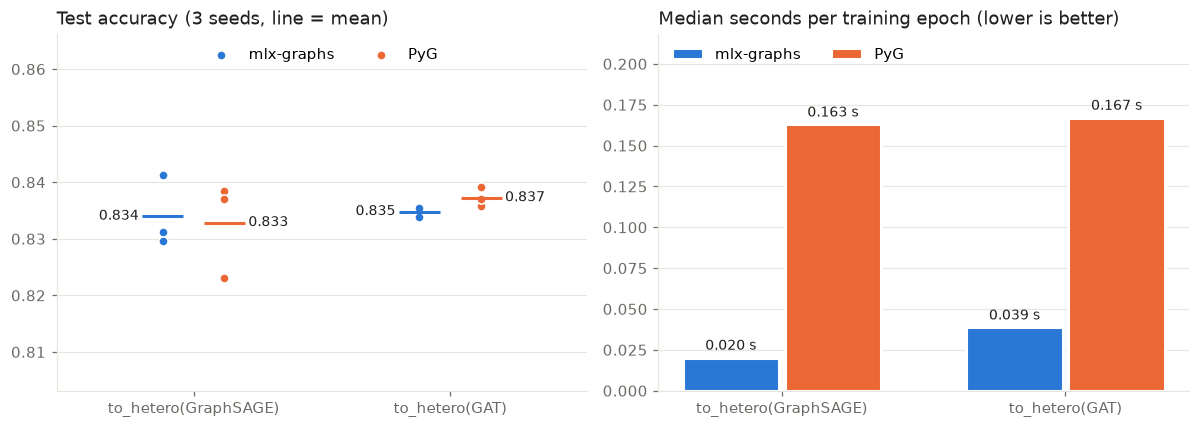

In [23]:
import matplotlib.pyplot as plt

COLORS = {"mlx-graphs": "#2a78d6", "PyG": "#eb6834"}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
FRAMEWORKS = ["mlx-graphs", "PyG"]
MODEL_NAMES = list(MLX_MODELS)

fig, (ax_acc, ax_time) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(MODEL_NAMES))
x_acc = 1.5 * x  # more room for the mean labels
width = 0.36

for i, framework in enumerate(FRAMEWORKS):
    offset = (i - 0.5) * width
    # test accuracy: one dot per seed, and the mean as a short line
    for j, name in enumerate(MODEL_NAMES):
        selected = (runs["framework"] == framework) & (runs["model"] == name)
        accs = runs.loc[selected, "test_acc"]
        ax_acc.scatter(
            np.full(len(accs), x_acc[j] + offset),
            accs,
            s=36,
            color=COLORS[framework],
            edgecolor="white",
            linewidth=1,
            zorder=3,
            label=framework if j == 0 else None,
        )
        ax_acc.hlines(
            accs.mean(),
            x_acc[j] + offset - 0.12,
            x_acc[j] + offset + 0.12,
            color=COLORS[framework],
            linewidth=2,
            zorder=3,
        )
        # mean labels on the outer side of each pair, away from the other line
        ax_acc.annotate(
            f"{accs.mean():.3f}",
            (x_acc[j] + offset + (0.14 if i else -0.14), accs.mean()),
            ha="left" if i else "right",
            va="center",
            fontsize=9,
            color=INK,
        )
    # time per epoch
    values = [summary.loc[(n, framework), "ms_per_epoch"] / 1000 for n in MODEL_NAMES]
    bars = ax_time.bar(
        x + offset,
        values,
        width - 0.02,
        color=COLORS[framework],
        edgecolor="white",
        linewidth=2,
        label=framework,
    )
    for bar, value in zip(bars, values):
        ax_time.annotate(
            f"{value:.3f} s",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color=INK,
            fontsize=9,
        )

ax_acc.set_ylim(runs["test_acc"].min() - 0.02, runs["test_acc"].max() + 0.025)
ax_acc.set_xlim(x_acc[0] - 0.8, x_acc[-1] + 0.8)
ax_acc.set_title(
    f"Test accuracy ({len(SEEDS)} seeds, line = mean)", loc="left", color=INK
)
ax_time.set_title(
    "Median seconds per training epoch (lower is better)", loc="left", color=INK
)
ax_time.set_ylim(0, runs["epoch_s"].max() * 1.25)
for ax in (ax_acc, ax_time):
    ticks = x_acc if ax is ax_acc else x
    ax.set_xticks(ticks, [f"to_hetero({n})" for n in MODEL_NAMES])
    ax.legend(
        frameon=False, loc="upper center" if ax is ax_acc else "upper left", ncol=2
    )
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
fig.tight_layout()
plt.show()

**Accuracy.** With the same data, architecture, optimizer and model selection, the two frameworks reach the same test accuracy, around 0.83 for both models. The differences between mlx-graphs and PyG are of the same size as the differences between seeds (see the standard deviations in the table): DBLP has only 400 training authors, so the random initialization and dropout matter more than the framework.

**Runtime.** These timings were measured on an Apple M5 Pro, with mlx-graphs on the GPU and PyG on the CPU (with the number of threads printed above). An mlx-graphs training epoch is several times faster than a PyG one for both models; the speedups printed above give the exact factors of this run. Timings vary from run to run and from machine to machine, so run the notebook on your own machine to compare.

## 7. Fewer parameters with `to_hetero_with_bases`

`to_hetero` creates one copy of every message passing layer per edge type, so the number of parameters grows with the number of relations. On graphs with many relations (knowledge graphs have hundreds), this means many parameters and a risk of overfitting the rare relations. The **basis decomposition** of [R-GCN](https://arxiv.org/abs/1703.06103) shares the work: `to_hetero_with_bases` keeps `num_bases` copies of every layer, runs them on the whole graph at once, and learns for every edge type one coefficient per basis that scales its messages. The number of parameters then depends on `num_bases`, not on the number of edge types.

All node types must have the same input size, since the copies are shared by all node types. `in_channels={"node_features": HIDDEN}` adds a bias-free linear projection per node type of the `node_features` argument to `HIDDEN` features (PyG's `LinearAlign`), and `input_dims` gives the input sizes of these projections. `to_hetero_with_bases` also needs layers that do not add self-loops.

In [24]:
mx.random.seed(0)
bases_sage = to_hetero_with_bases(
    MLX_MODELS["GraphSAGE"](),
    data.metadata(),
    num_bases=3,
    in_channels={"node_features": HIDDEN},
    input_dims=data.num_node_features,
)
mx.random.seed(0)
plain_sage = to_hetero(
    MLX_MODELS["GraphSAGE"](), data.metadata(), input_dims=data.num_node_features
)
n_plain, n_bases = count_parameters(plain_sage), count_parameters(bases_sage)
n_align = sum(v.size for _, v in tree_flatten(bases_sage.align))
print(f"to_hetero(GraphSAGE):            {n_plain:>9,} parameters")
print(f"to_hetero_with_bases(GraphSAGE): {n_bases:>9,} parameters")
print(f"  of which input projections:    {n_align:>9,}")
print(f"  of which message passing:      {n_bases - n_align:>9,}")

to_hetero(GraphSAGE):            1,677,464 parameters
to_hetero_with_bases(GraphSAGE):   321,776 parameters
  of which input projections:      295,424
  of which message passing:         26,352


Most parameters of both models are in the input weights for the 4,231 paper features. The `to_hetero` model has six of them in its first layer, one for every edge type whose source is a paper and one for the root weight of every edge type whose destination is a paper, while the basis model projects the paper features once. With six edge types, DBLP is a small case: the gap grows with the number of relations. The edge-type coefficients are visible in the parameters:

In [25]:
first_bases = bases_sage.module.convs[0]
first_bases.convs[0].edge_type_weight

array([[0.783287, 0.765768, 0.203009, 0.0670601, -0.17145, -0.903623]], dtype=float32)

In [26]:
mx.random.seed(0)
bases_result = train_full_batch(bases_sage, hetero_forward)
print(
    f"to_hetero_with_bases(GraphSAGE): test {bases_result['test_acc']:.4f}  "
    f"{1000 * bases_result['epoch_s']:.1f} ms/epoch"
)
del plain_sage

to_hetero_with_bases(GraphSAGE): test 0.8001  21.6 ms/epoch


The basis model does different work per epoch: it runs three copies of each layer on the whole graph, and the scaling of the messages by edge type bypasses the fused sparse kernels of mlx-graphs, but it projects the 4,231 paper features once instead of six times. The overview table of section 10 compares its accuracy and epoch time with the other models. The basis decomposition is mainly a tool against too many parameters, when a graph has many relations.

## 8. Native heterogeneous layers

`to_hetero` turns a homogeneous design into a heterogeneous one. mlx-graphs also has layers that are heterogeneous by design, which take `x_dict` and `edge_index_dict` directly, as in PyG:

- `HeteroDictLinear` applies one linear layer per node type: it maps node types of different sizes to a common size.
- `HeteroConv` wraps one homogeneous layer per edge type, chosen by you (the layer may differ between edge types), and combines the results per destination node type. It is the explicit form of what `to_hetero` builds automatically.
- `HGTConv` is the Heterogeneous Graph Transformer layer ([Hu et al., 2020](https://arxiv.org/abs/2003.01332)): attention over the neighbors of all edge types, with per-type keys, queries, values and per-relation attention matrices.
- `HANConv` is the Heterogeneous Graph Attention Network layer ([Wang et al., 2019](https://arxiv.org/abs/1903.07293)): a GAT per edge type, then a semantic attention that weighs the edge types.

The three models below start with `HeteroDictLinear` to project every node type to `HIDDEN` features, apply two heterogeneous layers, and classify the authors with a linear layer.

In [27]:
class HeteroSAGE(nn.Module):
    """HeteroDictLinear, then two HeteroConv layers with one SAGEConv per
    edge type."""

    def __init__(self, input_dims, edge_types, hidden, out, dropout):
        super().__init__()
        self.proj = HeteroDictLinear(input_dims, hidden)
        self.convs = [
            HeteroConv({et: SAGEConv(hidden, hidden) for et in edge_types}, aggr="sum")
            for _ in range(2)
        ]
        self.dropout = nn.Dropout(dropout)
        self.lin = nn.Linear(hidden, out)

    def __call__(self, x_dict, edge_index_dict):
        h = {t: nn.relu(x) for t, x in self.proj(x_dict).items()}
        for conv in self.convs:
            h = conv(h, edge_index_dict)
            h = {t: self.dropout(nn.relu(x)) for t, x in h.items()}
        return self.lin(h[TARGET])


class HGT(nn.Module):
    """HeteroDictLinear, then two HGTConv layers (as PyG's hgt_dblp.py)."""

    def __init__(self, input_dims, metadata, hidden, out, heads):
        super().__init__()
        self.proj = HeteroDictLinear(input_dims, hidden)
        self.convs = [HGTConv(hidden, hidden, metadata, heads=heads) for _ in range(2)]
        self.lin = nn.Linear(hidden, out)

    def __call__(self, x_dict, edge_index_dict):
        h = {t: nn.relu(x) for t, x in self.proj(x_dict).items()}
        for conv in self.convs:
            h = conv(h, edge_index_dict)
        return self.lin(h[TARGET])


class HAN(nn.Module):
    """Two HANConv layers (each projects its inputs per node type)."""

    def __init__(self, input_dims, metadata, hidden, out, heads, dropout):
        super().__init__()
        self.conv1 = HANConv(input_dims, hidden, metadata, heads=heads, dropout=dropout)
        self.conv2 = HANConv(hidden, hidden, metadata, heads=heads, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.lin = nn.Linear(hidden, out)

    def __call__(self, x_dict, edge_index_dict):
        h = self.conv1(x_dict, edge_index_dict)
        h = {t: self.dropout(x) for t, x in h.items()}
        h = self.conv2(h, edge_index_dict)
        return self.lin(h[TARGET])


NATIVE_MODELS = {
    "HeteroConv(SAGEConv)": lambda: HeteroSAGE(
        data.num_node_features, data.edge_types, HIDDEN, NUM_CLASSES, DROPOUT
    ),
    "HGTConv": lambda: HGT(
        data.num_node_features, data.metadata(), HIDDEN, NUM_CLASSES, heads=2
    ),
    "HANConv": lambda: HAN(
        data.num_node_features, data.metadata(), HIDDEN, NUM_CLASSES, HEADS, DROPOUT
    ),
}


def native_forward(model):
    return model(data.node_features_dict, data.edge_index_dict)


native_runs = []
for name, make_model in NATIVE_MODELS.items():
    mx.random.seed(0)
    model = make_model()
    result = train_full_batch(model, native_forward)
    native_runs.append({"model": name, "parameters": count_parameters(model), **result})
    print(
        f"{name:<21} {count_parameters(model):>9,} parameters  "
        f"test {result['test_acc']:.4f}  {1000 * result['epoch_s']:.1f} ms/epoch"
    )

HeteroConv(SAGEConv)    395,012 parameters  test 0.8096  7.9 ms/epoch
HGTConv                 478,244 parameters  test 0.7636  19.3 ms/epoch
HANConv                 322,564 parameters  test 0.8096  13.2 ms/epoch


Projecting the features first makes these models much smaller than the `to_hetero` ones, whose first layer reads the raw features once per edge type. `HANConv` was designed for **metapath** graphs, where an edge connects two authors that share a paper (author-paper-author) or a conference: here we apply it to the raw relations to show its API, without building metapaths. Its node-level attention has no root weight, so an author only sees its own features through two hops.

`HANConv` can also return its semantic attention weights, which tell how much each edge type contributes to a node type. Papers receive messages from authors, terms and conferences:

In [28]:
han = model  # the last model trained above
han.eval()
_, semantic = han.conv1(
    data.node_features_dict,
    data.edge_index_dict,
    return_semantic_attention_weights=True,
)
incoming = [et for et in data.edge_types if et[-1] == "paper"]
dict(zip([f"{src} -> paper" for src, _, _ in incoming], semantic["paper"].tolist()))

{'author -> paper': 0.999995231628418, 'term -> paper': 1.6165221268238383e-06, 'conference -> paper': 3.0664973564853426e-06}

The weights sum to one over the incoming edge types, and show which relations the trained model relies on to build the paper representations.

## 9. Mini-batch training with `NeighborLoader` and `HGTLoader`

Full-batch training needs the whole graph and all its intermediate activations in memory. On large graphs, mini-batches of sampled subgraphs are the way out: every batch holds a set of **seed** nodes (here, training authors) and a sample of their multi-hop neighborhood, just large enough to compute the seeds' representations. mlx-graphs has the two heterogeneous samplers of PyG:

- `NeighborLoader` samples a fixed number of neighbors per node, per edge type and per hop (`num_neighbors=[10, 10]`: 10 neighbors per edge type at each of the 2 hops), as in GraphSAGE.
- `HGTLoader` samples a fixed **budget of nodes per node type** at each hop (`num_samples`), favoring nodes connected to many already sampled nodes. It keeps the size of the batches under control even around very high-degree nodes, and was introduced with HGT for ogbn-mag-sized graphs.

Both sample on the host, outside the GPU, and return a `HeteroGraphData` per batch. PyG's versions of these loaders need the optional `pyg-lib` (or `torch-sparse`) package, which is not installed here, so this section is mlx-graphs only.

In [29]:
np.random.seed(0)  # the samplers draw with NumPy
neighbor_loader = NeighborLoader(
    data,
    num_neighbors=[10, 10],
    input_nodes=(TARGET, data.author_train_mask),
    batch_size=128,
    shuffle=True,
)
hgt_loader = HGTLoader(
    data,
    num_samples=[256, 256],
    input_nodes=(TARGET, data.author_train_mask),
    batch_size=128,
    shuffle=True,
)

batch = next(iter(neighbor_loader))
print(batch)

HeteroGraphData(
node_features(
  'author': (shape=(317, 334), float32),
  'paper': (shape=(515, 4231), float32),
  'term': (shape=(1217, 50), float32),
  'conference': (shape=(19, 1), float32),
)
 edge_index(
  'author -> to -> paper':(shape=(2, 868), int64),
  'paper -> to -> author':(shape=(2, 517), int64),
  'paper -> to -> term':(shape=(2, 0), int64),
  'paper -> to -> conference':(shape=(2, 0), int64),
  'term -> to -> paper':(shape=(2, 3173), int64),
  'conference -> to -> paper':(shape=(2, 515), int64),
)
 edge_labels_index_dict(
)
 edge_labels_dict(
)
node_labels_dict(
  'author': (shape=(317,),int64),
)
batch_size=128
input_type=author
n_id_dict(
  'author': (shape=(317,),int32),
  'paper': (shape=(515,),int32),
  'term': (shape=(1217,),int32),
  'conference': (shape=(19,),int32),
)
e_id_dict(
  '('author', 'to', 'paper')': (shape=(868,),int32),
  '('paper', 'to', 'author')': (shape=(517,),int32),
  '('paper', 'to', 'term')': (shape=(0,),int32),
  '('paper', 'to', 'conference

A batch is a subgraph with **local** node ids per node type. `n_id_dict` maps them back to the global ids of the full graph. The first `batch_size` authors are the seed nodes, so the loss is computed on `out["author"][:batch.batch_size]`. `num_sampled_nodes_dict` counts the nodes added at each hop, starting with the seeds. Here is what one batch of each loader contains:

In [30]:
def describe(batch):
    nodes = {t: n_id.size for t, n_id in batch.n_id_dict.items()}
    edges = {f"{s}->{d}": e.shape[1] for (s, _, d), e in batch.edge_index_dict.items()}
    hops = {t: list(c) for t, c in batch.num_sampled_nodes_dict.items()}
    return nodes, edges, hops


np.random.seed(0)
for name, loader in [("NeighborLoader", neighbor_loader), ("HGTLoader", hgt_loader)]:
    batch = next(iter(loader))
    nodes, edges, hops = describe(batch)
    print(f"{name}: batch_size={batch.batch_size}, input_type={batch.input_type!r}")
    print(f"  nodes per type:  {nodes}")
    print(f"  nodes per hop:   {hops}")
    print(f"  edges per type:  {edges}")
    print(f"  first seed ids:  {batch.n_id_dict[TARGET][:5].tolist()}")

NeighborLoader: batch_size=128, input_type='author'
  nodes per type:  {'author': 312, 'paper': 466, 'term': 1109, 'conference': 19}
  nodes per hop:   {'author': [128, 0, 184], 'paper': [0, 466, 0], 'term': [0, 0, 1109], 'conference': [0, 0, 19]}
  edges per type:  {'author->paper': 755, 'paper->author': 466, 'paper->term': 0, 'paper->conference': 0, 'term->paper': 2836, 'conference->paper': 466}
  first seed ids:  [735, 3500, 3687, 1581, 1177]
HGTLoader: batch_size=128, input_type='author'
  nodes per type:  {'author': 249, 'paper': 512, 'term': 256, 'conference': 18}
  nodes per hop:   {'author': [128, 0, 121], 'paper': [0, 256, 256], 'term': [0, 0, 256], 'conference': [0, 0, 18]}
  edges per type:  {'author->paper': 751, 'paper->author': 732, 'paper->term': 517, 'paper->conference': 30, 'term->paper': 1589, 'conference->paper': 508}
  first seed ids:  [3764, 1757, 1443, 508, 1758]


The training loop iterates over the batches and computes the loss on the seed authors. The models are the same `to_hetero(GraphSAGE)` as before: a converted model runs on any subgraph whose node and edge types are in its metadata. DBLP has only 400 training authors, so an epoch is just four batches. After each epoch we evaluate on the whole graph, which still fits in memory (on a larger graph, use a loader with all neighbors, `num_neighbors=[-1, -1]`, over the validation and test nodes).

In [31]:
def train_mini_batch(model, loader, epochs=MINI_BATCH_EPOCHS):
    optimizer = optim.AdamW(LR, weight_decay=WEIGHT_DECAY, bias_correction=True)

    def loss_fn(model, batch):
        out = model(batch.edge_index_dict, batch.node_features_dict)[TARGET]
        n = batch.batch_size
        return nn.losses.cross_entropy(
            out[:n], batch.node_labels_dict[TARGET][:n], reduction="mean"
        )

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    best_val, test_at_best, times = -1.0, 0.0, []
    for _ in range(epochs):
        model.train()
        start = time.perf_counter()
        for batch in loader:
            loss, grads = loss_and_grad(model, batch)
            optimizer.update(model, grads)
            mx.eval(model.parameters(), optimizer.state, loss)
        times.append(time.perf_counter() - start)

        model.eval()
        logits = hetero_forward(model)
        val_acc, test_acc = (
            accuracy(logits, masks["val"]),
            accuracy(logits, masks["test"]),
        )
        if val_acc > best_val:
            best_val, test_at_best = val_acc, test_acc
    return {
        "val_acc": best_val,
        "test_acc": test_at_best,
        "epoch_s": float(np.median(times[1:])),
    }


mini_batch_runs = []
for name, loader in [("NeighborLoader", neighbor_loader), ("HGTLoader", hgt_loader)]:
    mx.random.seed(0)
    np.random.seed(0)
    model = to_hetero(
        MLX_MODELS["GraphSAGE"](), data.metadata(), input_dims=data.num_node_features
    )
    result = train_mini_batch(model, loader)
    mini_batch_runs.append({"loader": name, **result})
    print(
        f"to_hetero(GraphSAGE) + {name:<14}: test {result['test_acc']:.4f}  "
        f"{1000 * result['epoch_s']:.0f} ms/epoch (sampling included)"
    )

to_hetero(GraphSAGE) + NeighborLoader: test 0.8351  21 ms/epoch (sampling included)
to_hetero(GraphSAGE) + HGTLoader     : test 0.8357  42 ms/epoch (sampling included)


The epoch times include the sampling. An epoch here makes four optimizer steps on small subgraphs, where a full-batch epoch makes one step on the whole graph, so the two kinds of epochs are not directly comparable. On a graph as small as DBLP, full-batch training is the simpler choice; mini-batches become necessary when the graph or its activations no longer fit in memory.

## 10. Which tool for what

All the mlx-graphs models of this tutorial, trained on DBLP with the same optimizer (one seed for the models outside the comparison with PyG):

In [32]:
overview = [
    {
        "approach": f"to_hetero({name}), full batch",
        "test acc": summary.loc[(name, "mlx-graphs"), "test_acc_mean"],
        "ms/epoch": summary.loc[(name, "mlx-graphs"), "ms_per_epoch"],
    }
    for name in MLX_MODELS
]
overview.append(
    {
        "approach": "to_hetero_with_bases(GraphSAGE), full batch",
        "test acc": bases_result["test_acc"],
        "ms/epoch": 1000 * bases_result["epoch_s"],
    }
)
overview += [
    {
        "approach": f"{r['model']}, full batch",
        "test acc": r["test_acc"],
        "ms/epoch": 1000 * r["epoch_s"],
    }
    for r in native_runs
]
overview += [
    {
        "approach": f"to_hetero(GraphSAGE), {r['loader']}",
        "test acc": r["test_acc"],
        "ms/epoch": 1000 * r["epoch_s"],
    }
    for r in mini_batch_runs
]
pd.DataFrame(overview).set_index("approach").round({"test acc": 4, "ms/epoch": 1})

,test acc,ms/epoch
approach,,
"to_hetero(GraphSAGE), full batch",0.8340,20.2
"to_hetero(GAT), full batch",0.8348,38.7
"to_hetero_with_bases(GraphSAGE), full batch",0.8001,21.6
"HeteroConv(SAGEConv), full batch",0.8096,7.9
"HGTConv, full batch",0.7636,19.3
"HANConv, full batch",0.8096,13.2
"to_hetero(GraphSAGE), NeighborLoader",0.8351,21.0
"to_hetero(GraphSAGE), HGTLoader",0.8357,41.7


The models outside the PyG comparison were trained with a single seed and without tuning, and on 400 training authors the seed alone moves the test accuracy by a point or two (see section 6): read these numbers as indications, not as a ranking. What the table does show is the trade-offs:

- **`to_hetero`** is the shortest path from an existing homogeneous model, built-in or your own, to a heterogeneous one, and it is the one that mirrors PyG's API one-to-one. Its parameter count grows with the number of edge types and with the input sizes, since its first layer reads the raw features once per edge type.
- **`to_hetero_with_bases`** keeps the parameter count independent of the number of edge types. Use it when a graph has many relations.
- **`HeteroDictLinear` + `HeteroConv`** spell out the same idea by hand, with full control: a different layer per edge type, a projection to a common size first (which made the models of section 8 much smaller here). **`HGTConv`** and **`HANConv`** add attention across node and edge types.
- **`NeighborLoader` and `HGTLoader`** train any of these models on sampled subgraphs, for graphs that do not fit in memory, at the cost of the sampling time.

## 11. Larger graphs: ogbn-mag

The same tools scale to the `ogbn-mag` benchmark of the Open Graph Benchmark, available as `mlx_graphs.datasets.OGBMAG`: 1.9 million nodes of four types (papers, authors, institutions, fields of study) and 21 million edges, where the task is to predict the venue of each paper among 349. We do not run it here, since its download is 430 MB. The recipe is the one of sections 3 and 9:

```python
from mlx_graphs.datasets import OGBMAG

data = OGBMAG.add_reverse_edges(OGBMAG()[0])  # authors etc. must receive messages
# only papers have features: give the other node types learned or constant ones,
# e.g. a constant feature as for the DBLP conferences above
loader = HGTLoader(
    data,
    num_samples=[512] * 2,
    input_nodes=("paper", data.paper_train_mask),
    batch_size=1024,
    shuffle=True,
)
model = to_hetero(GraphSAGE(...), data.metadata(), input_dims=...)
```

Full-batch training is out of reach at this size, so this is where `HGTLoader` and `NeighborLoader` are needed. `OGBMAG.add_reverse_edges` adds a `rev_` edge type for every relation between two node types and makes `paper -cites-> paper` undirected, like PyG's `ToUndirected`.

## Going further

- [examples/to_hetero_dblp.py](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/to_hetero_dblp.py) is a command-line version of sections 3, 4 and 9, and [examples/hetero_sage_dblp.py](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/hetero_sage_dblp.py) a `HeteroConv` model trained with `NeighborLoader`.
- `mlx_graphs.datasets` has other heterogeneous datasets: `IMDB`, `MovieLens100K` and `FakeHeteroDataset` (random graphs for tests).
- `HeteroBatchNormalization` and `HeteroLayerNormalization` normalize every node type separately in hand-written heterogeneous models.